## <span style="color:#1F4E79;">__Optimization of the Bradley–Terry Likelihood__</span>

***This notebook implements full-batch gradient descent, stochastic gradient descent, mini-batch gradient descent, momentum and Adam. The same methods are then reproduced using PyTorch and compared in terms of convergence, parameter recovery, computational cost and stability.***

In [1]:
# Import numerical, tabular, plotting and Bradley-Terry utilities.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bradley_terry import *

##### Reusable Bradley–Terry Functions

| Function | Purpose |
|---|---|
| `center_parameters()` | Shifts parameters so their mean is zero. |
| `generate_uniform_comparison_data()` | Generates observations as `(winner, loser)` pairs. |
| `average_negative_log_likelihood()` | Evaluates the full-data Bradley–Terry NLL. |
| `parameter_recovery_error()` | Calculates RMSE between true and estimated parameters. |
| `ford_condition_holds()` | Checks whether the directed win graph permits a finite MLE. |
| `optimize_with_full_batch_gradient_descent()` | Uses the complete dataset for every parameter update. |
| `optimize_with_stochastic_gradient_descent()` | Uses one comparison for every parameter update. |
| `optimize_with_minibatch_gradient_descent()` | Uses a small batch of comparisons for each update. |
| `optimize_with_momentum_gradient_descent()` | Adds accumulated gradient direction to mini-batch SGD. |
| `optimize_with_adam()` | Uses adaptive step sizes and first- and second-moment estimates. |
| `OptimizationResult` | Stores parameters, NLL history, update counts and runtime consistently. |

In [2]:
# Define settings shared by every handcrafted optimizer.

SEED = 20260831
NUMBER_OF_ITEMS = 10
NUMBER_OF_COMPARISONS = 10_000
MINIBATCH_SIZE = 128

rng = np.random.default_rng(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 5)

experiment_settings = pd.DataFrame({
    "setting": [
        "Random seed",
        "Number of items",
        "Number of comparisons",

        "Mini-batch size",
    ],
    "value": [
        SEED,
        NUMBER_OF_ITEMS,
        NUMBER_OF_COMPARISONS,
        MINIBATCH_SIZE,
    ],
})

experiment_settings

,setting,value
0,Random seed,20260831
1,Number of items,10
2,Number of comparisons,10000
3,Mini-batch size,128


### <span style="color:#1F4E79;">Experiment 1: Common Dataset for Handcrafted Optimizers</span>

One single Bradley–Terry dataset is generated and held fixed throughout this experiment. Every optimizer therefore receives exactly the same observations and starts from the same zero parameter vector. So the optimization methods can be compared

In [3]:
# Generate true parameters and one common comparison dataset.

item_names = [
    f"Item {item_index}"
    for item_index in range(NUMBER_OF_ITEMS)
]

true_parameters = center_parameters(
    rng.normal(
        loc=0.0,
        scale=0.8,
        size=NUMBER_OF_ITEMS,
    )
)

comparisons = generate_uniform_comparison_data(
    true_parameters=true_parameters,
    number_of_comparisons=NUMBER_OF_COMPARISONS,
    rng=rng,
)

true_parameter_table = pd.DataFrame({
    "item": item_names,
    "true_parameter": true_parameters,
})

print("Number of observations:", len(comparisons))
print("First five (winner, loser) pairs:", comparisons[:5])

true_parameter_table

Number of observations: 10000
First five (winner, loser) pairs: [(1, 4), (8, 9), (0, 8), (0, 4), (3, 7)]


,item,true_parameter
0,Item 0,0.04995
1,Item 1,0.09685
2,Item 2,0.48274
3,Item 3,1.56037
4,Item 4,-0.35400
5,Item 5,-1.17337
6,Item 6,-0.17237
7,Item 7,0.00647
8,Item 8,-0.59657
9,Item 9,0.09993


In [4]:
# Summarize item appearances and verify Ford's condition.

comparison_array = np.asarray(
    comparisons,
    dtype=int,
)

wins = np.bincount(
    comparison_array[:, 0],
    minlength=NUMBER_OF_ITEMS,
)

losses = np.bincount(
    comparison_array[:, 1],
    minlength=NUMBER_OF_ITEMS,
)

appearances = wins + losses
empirical_win_rates = wins / appearances

comparison_summary_table = pd.DataFrame({
    "item": item_names,
    "true_parameter": true_parameters,
    "wins": wins,
    "losses": losses,
    "appearances": appearances,
    "empirical_win_rate": empirical_win_rates,
})

print(
    "Ford's condition holds:",
    ford_condition_holds(
        NUMBER_OF_ITEMS,
        comparisons,
    ),
)

comparison_summary_table

Ford's condition holds: True


,item,true_parameter,wins,losses,appearances,empirical_win_rate
0,Item 0,0.04995,1033,958,1991,0.51883
1,Item 1,0.09685,1028,927,1955,0.52583
2,Item 2,0.48274,1267,793,2060,0.61505
3,Item 3,1.56037,1702,309,2011,0.84635
4,Item 4,-0.35400,838,1133,1971,0.42516
5,Item 5,-1.17337,467,1567,2034,0.22960
6,Item 6,-0.17237,869,1093,1962,0.44292
7,Item 7,0.00647,1038,934,1972,0.52637
8,Item 8,-0.59657,712,1309,2021,0.35230
9,Item 9,0.09993,1046,977,2023,0.51705


### <span style="color:#1F4E79;">Experiment 2: Handcrafted Full-Batch Gradient Descent</span>

For \(m\) observed winner–los pairs, the average Bradley–Terry negative log-likelihood is

$$
\mathcal{L}(\boldsymbol{\theta})
=
\frac{1}{m}
\sum_{(w,l)}
\log\left(
1+\exp[-(\theta_w-\theta_l)]
\right).
$$

Full-batch gradient descent calculates the gradient using all \(m\) observations before making one update:

$$
\boldsymbol{\theta}^{(t+1)}
=
\boldsymbol{\theta}^{(t)}
-
\eta
\nabla\mathcal{L}
\left(
\boldsymbol{\theta}^{(t)}
\right),
$$

where 'etta' is the learning rate.

After every update, the parameters are centred:

$$
\boldsymbol{\theta}
\leftarrow
\boldsymbol{\theta}
-
\frac{1}{n}
\sum_{i=1}^{n}\theta_i.
$$

Therefore, one full-batch update corresponds to one complete pass, or one epoch, through the comparison dataset.

In [5]:
# Fit the Bradley-Terry model using handcrafted full-batch GD.

full_batch_learning_rate = 0.1

full_batch_result = (
    optimize_with_full_batch_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=full_batch_learning_rate,
        
    )
)

full_batch_recovery_error = parameter_recovery_error(
    true_parameters,
    full_batch_result.parameters,
)

full_batch_summary = pd.DataFrame({
    "quantity": [
        "Learning rate",
        "Initial full-data NLL",
        "Final full-data NLL",
        "Parameter-recovery RMSE",
        "Number of updates",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "value": [
        f"{full_batch_learning_rate:.4f}",
        f"{full_batch_result.nll_history[0]:.4f}",
        f"{full_batch_result.nll_history[-1]:.4f}",
        f"{full_batch_recovery_error:.4f}",
        str(
            int(
                full_batch_result
                .update_count_history[-1]
            )
        ),
        f"{full_batch_result.runtime_seconds:.4f}",
        f"{full_batch_result.parameters.sum():.4f}",
    ],
})

full_batch_summary

,quantity,value
0,Learning rate,0.1000
1,Initial full-data NLL,0.6931
2,Final full-data NLL,0.5982
3,Parameter-recovery RMSE,0.0383
4,Number of updates,3706
5,Runtime in seconds,2.0316
6,Sum of estimated parameters,-0.0000


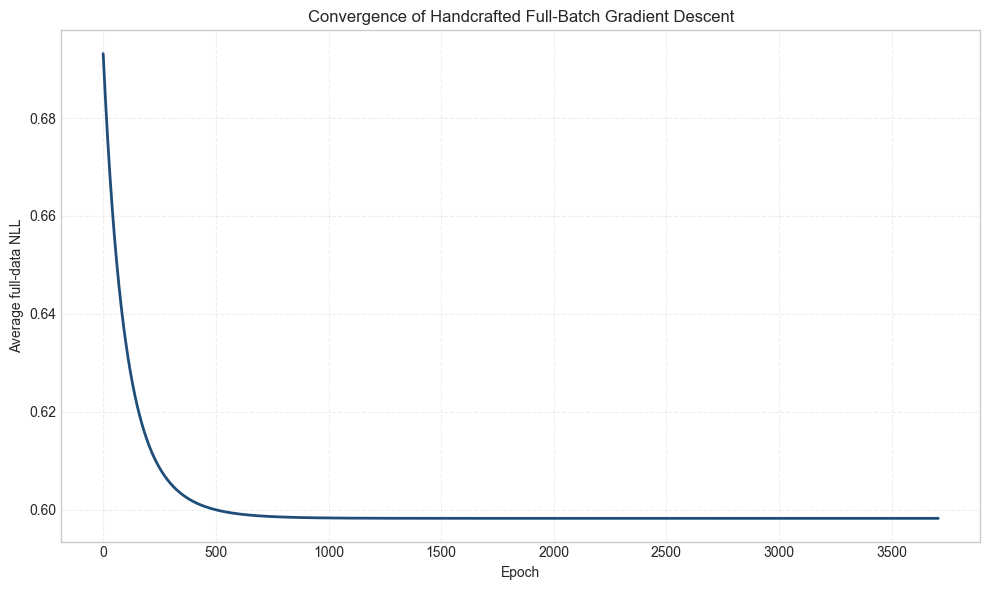

In [6]:
# Plot the full-data NLL after every full-batch update.

full_batch_epochs = np.arange(
    len(full_batch_result.nll_history)
)

fig, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    full_batch_epochs,
    full_batch_result.nll_history,
    color="#1F4E79",
    linewidth=2,
)

axis.set_xlabel("Epoch")
axis.set_ylabel("Average full-data NLL")
axis.set_title(
    "Convergence of Handcrafted Full-Batch Gradient Descent"
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.35,
)

plt.tight_layout()
plt.show()

In [9]:
# Inspect NLL, gradient and parameter changes at selected epochs.

nll_values = np.asarray(
    full_batch_result.nll_history
)

gradient_norms = np.asarray(
    full_batch_result.gradient_norm_history
)

parameter_history = np.asarray(
    full_batch_result.parameter_history
)

last_epoch = full_batch_result.epochs_completed

requested_epochs = [
    0,
    1,
    10,
    50,
    100,
    500,
    1_000,
    1_500,
    2_000,
    2_500,
    3_000,
    3_500,
    last_epoch,
]

selected_epochs = sorted({
    epoch
    for epoch in requested_epochs
    if epoch <= last_epoch
})

inspection_rows = []

for epoch in selected_epochs:
    if epoch == 0:
        nll_decrease = np.nan
        parameter_change = np.nan
    else:
        nll_decrease = (
            nll_values[epoch - 1]
            - nll_values[epoch]
        )

        parameter_change = np.linalg.norm(
            parameter_history[epoch]
            - parameter_history[epoch - 1]
        )

    inspection_rows.append({
        "epoch": epoch,
        "NLL": nll_values[epoch],
        "NLL decrease from previous epoch": nll_decrease,
        "distance from final NLL": (
            nll_values[epoch]
            - nll_values[-1]
        ),
        "gradient norm": gradient_norms[epoch],
        "parameter change": parameter_change,
    })

nll_inspection_table = pd.DataFrame(
    inspection_rows
)

display(
    nll_inspection_table.style.format({
        "NLL": "{:.10f}",
        "NLL decrease from previous epoch": "{:.4e}",
        "distance from final NLL": "{:.4e}",
        "gradient norm": "{:.4e}",
        "parameter change": "{:.4e}",
    })
)

,epoch,NLL,NLL decrease from previous epoch,distance from final NLL,gradient norm,parameter change
0,0,0.6931471806,nan,9.4913e-02,9.8744e-02,nan
1,1,0.6921749063,9.7227e-04,9.3941e-02,9.8185e-02,9.8744e-03
2,10,0.6839037594,8.7786e-04,8.5670e-02,9.3296e-02,9.3827e-03
3,50,0.6557934579,5.6071e-04,5.7560e-02,7.4572e-02,7.4984e-03
4,100,0.6342560170,3.2842e-04,3.6022e-02,5.7086e-02,5.7382e-03
5,500,0.5999789820,1.1632e-05,1.7450e-03,1.0756e-02,1.0795e-03
6,1000,0.5983130613,4.6800e-07,7.9117e-05,2.1585e-03,2.1650e-04
7,1500,0.5982383496,2.5165e-08,4.4051e-06,5.0057e-04,5.0200e-05
8,2000,0.5982342042,1.4688e-09,2.5973e-07,1.2094e-04,1.2128e-05
9,2500,0.5982339601,8.7791e-11,1.5555e-08,2.9567e-05,2.9650e-06


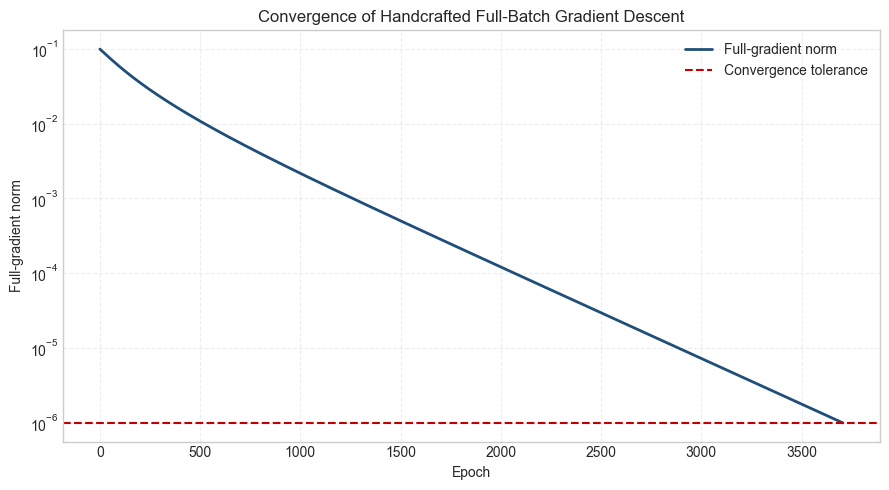

In [8]:
# Plot the full-gradient norm against the convergence threshold.

GRADIENT_TOLERANCE = 1e-6

full_batch_epochs = np.arange(
    len(full_batch_result.gradient_norm_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.semilogy(
    full_batch_epochs,
    full_batch_result.gradient_norm_history,
    color="#1F4E79",
    linewidth=2,
    label="Full-gradient norm",
)

axis.axhline(
    y=GRADIENT_TOLERANCE,
    color="#C00000",
    linestyle="--",
    linewidth=1.5,
    label="Convergence tolerance",
)

axis.set_xlabel("Epoch")
axis.set_ylabel("Full-gradient norm")
axis.set_title("Convergence of Handcrafted Full-Batch Gradient Descent")
axis.legend()
axis.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()